In [12]:
# INICIALIZAÇÃO DAS BIBLIOTECAS
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
#%matplotlib inline

In [13]:
def set_rho(ff, rho_fat = np.array(0.05)):
    '''
    This function calculates fat and water proton densities (rho_fat and rho_water), given a fat fraction value (ff).
    rho_fat is by default fixed as = 0.05, and can be optionally be passed as an argument.
    rho_water is calculated as a function of ff and rho_fat.
    Parameters: ff -> float 0>1
                rho_fat (optional) -> float >0
    Returns:    rho_fat -> float >0 
                rho_water -> float >0
    '''
    #rho_fat = np.array(0.05)
    rho_water = np.array((rho_fat*((1-ff)/ff)))
    return (rho_fat,rho_water)

In [14]:
def discrete_timeseries(n_echoes):
    '''
    This function calculates the GRE IP-OP signal echo times for fat-water studies at 3T, given the number of echoes.
    Parameters: n_echoes     -> integer >0, number of equally spaced echoes (standard values range from 2 to 7)
    Returns:    echo_times -> float >0, time in seconds (equivalent to xdata)
     '''
    
    #TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    
    return echo_times

In [15]:
def gen_GRE(echo_times, rho_fat, rho_water):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton (T2* and characteristic ppm frequency values).
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
    rho = np.array([rho_fat*0.047,\
    rho_fat*0.039,\
    rho_fat*0.006,\
    rho_fat*0.12,\
    rho_fat*0.7,\
    rho_fat*0.088,\
    rho_water]) #rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    
    #standard, individual T2* values
    t2star = np.array([0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023] )
    
    #frequency in parts per million for each moiety
    freq_ppm = np.array([5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.577e6) #Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    #calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    #obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    
    Sabs = np.absolute(np.sum(S, axis=0))
    return (Sabs)

In [25]:
def gen_GRE_t2(echo_times, rho_fat, rho_water, t2star=[0.030,0.040,0.051,0.052,0.062,0.083,0.023]):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton.
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
                t2star     -> array >0, T2* values for fat peaks at 5.3, 4.2, 2.75, 2.1, 1.3 and 0.9 ppm (fat) and water 
                returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
    rho = np.array([rho_fat*0.047,\
    rho_fat*0.039,\
    rho_fat*0.006,\
    rho_fat*0.12,\
    rho_fat*0.7,\
    rho_fat*0.088,\
    rho_water]) #rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    
    #standard, individual T2* values
    '''
    t2star = np.array([0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023] )
    '''
    #frequency in parts per million for each moiety
    freq_ppm = np.array([5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.577e6) #Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    #calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    #obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    Sabs = np.sum(S, axis=0)
    Sabs = np.absolute(np.sum(S, axis=0))
    return (Sabs)

In [75]:
def gen_GRE_t2_noise(echo_times, rho_fat, rho_water, t2star=[0.030,0.040,0.051,0.052,0.062,0.083,0.023], noise_sd=0.01):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton (T2* and characteristic ppm frequency values).
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
                t2star     -> array >0, T2* values for fat peaks at 5.3, 4.2, 2.75, 2.1, 1.3 and 0.9 ppm (fat) and water
                noise_sd   -> float >0, noise standard deviation as proportion of the first signal point intensity (default is 1% = 0.01)
    returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
    rho = np.array([rho_fat*0.047,\
    rho_fat*0.039,\
    rho_fat*0.006,\
    rho_fat*0.12,\
    rho_fat*0.7,\
    rho_fat*0.088,\
    rho_water]) #rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    
    #standard, individual T2* values
    '''
    t2star = np.array([0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023] )
    '''
    #frequency in parts per million for each moiety
    freq_ppm = np.array([5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.577e6) #Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    #calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    #obtain sum & add noise
    Ssum= (len(echo_times))
    Ssum=np.zeros(Ssum,dtype='complex')
    Ssum = np.sum(S, axis=0)
    
    for t,TE in enumerate(echo_times):
        Ssum[t] = Ssum[t].real+Ssum[0].real*np.random.normal(scale=noise_sd)+1j*(Ssum[t].imag+Ssum[0].imag*np.random.normal(scale=noise_sd))

    
    #obtain absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    Sabs = np.absolute(Ssum)
    return (Sabs)

In [18]:
def continuous_timeseries(endpoint=0.01):
    '''
    This function returns a timeseries consisting of 1000 points, by default ranging from t=0 to t=0.01.
    It is useful for plotting the fitted curve.
    Parameters: endpoint (optional) -> float >0, time in seconds to end the series
    Returns:    array -> float >0, time in seconds (equivalent to xdata)
    '''
    return np.linspace(0, endpoint, 1000, endpoint=True)   

In [19]:
def calc_fatfrac(fitted_parameters):
    '''
    This function calculates the fat fraction based on the fitted parameters for rho_fat and rho_water, where:
    rho_fat = fitted_parameters[0]
    rho_water = fitted_parameters[1]
    Parameters: fitted_parameters -> float (array), proton density for fat and water
    Returns:    scalar -> float >0, fat fraction
    '''
    return  fitted_parameters[0] / (fitted_parameters[0] + fitted_parameters[1])

In [20]:
def fit_multiinterf(echo_times, rho_fat, rho_water, t2star):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton (T2* and characteristic ppm frequency values).
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
    
    echo_times = np.array(echo_times)
    rho_fat = np.array(rho_fat)
    rho_water = np.array(rho_water)
    t2star = np.array(t2star)
    
    #cn is the fractional proton density of each fat moiety (Yokoo) (see freq_ppm)
    cn = np.array([0.12, 0.7, 0.088,]) 
    
    #frequency in parts per million for each fat moiety
    ppm_fat = np.array([2.1, 1.3, 0.9])
    ppm_water = np.array(4.7)
    
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.577e6) #Hydrogen gyromagnetic ratio, Hz/T
    freq_water = np.array(ppm_water*magField*hydroGyro/1e6) #water frequency in Hertz
    
    #relative frequency for each fat to that of water
    freqr_fat = np.zeros(len(ppm_fat))
    for n, fppm in enumerate(ppm_fat):
        freqr_fat[n] = freq_water-(fppm*magField*hydroGyro/1e6)
    
    #calculate the signal for each moiety    
    S = (len(freqr_fat),len(echo_times))
    S = np.zeros(S,dtype='complex')
        #three fat signals
    for n, moieties in enumerate(freqr_fat):
        for t,TE in enumerate(echo_times):
            S[n,t] = cn[n]*np.exp(2.0*np.pi*1j*freqr_fat[n]*TE)
    
    Ssum= len(echo_times)
    Ssum = np.zeros(Ssum)
    Ssum = np.sum(S, axis=0) #sum of fat signals
    Sabs = np.absolute(rho_water + rho_fat*Ssum) #multiply rho_fat and add rho_water, take absolute value
    Sfinal = len(echo_times)
    Sfinal = np.zeros(Sfinal)
    for t,TE in enumerate(echo_times):
        Sfinal[t] = Sabs[t]*np.exp(-TE/t2star) #exponential decay
    
    return (Sfinal)

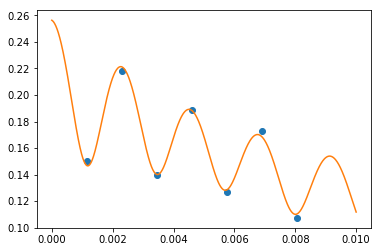

[ 0.05657862  0.20495221  0.01951048] 0.216336332468


In [76]:
#teste fit multi-interf
rf, rw = set_rho(0.2)

xdata = discrete_timeseries(7)
ydata = gen_GRE_t2_noise(xdata, rf, rw) #usa gen_GRE para gerar os pontos

bd = (0, [np.inf, np.inf, 1])
fitted_param, pcv = curve_fit(fit_multiinterf, xdata, ydata, bounds=bd) #tentar fitar com fit_multiinterf

x_cont = continuous_timeseries()
y_fit = fit_multiinterf(x_cont, *fitted_param)

xref = continuous_timeseries()
yref = gen_GRE_t2_noise(xref, rf, rw)

plt.plot(xdata,ydata,'o')
plt.plot(x_cont,y_fit,'-')
#plt.plot(xref, yref, '-')
plt.show()

ff_calc = calc_fatfrac(fitted_param)
print fitted_param, ff_calc

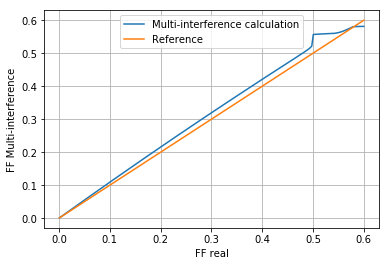

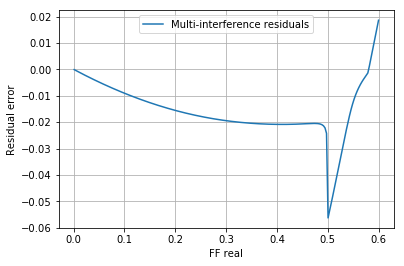

In [22]:
#fitting multi-interf com t2 fixos por hamilton

FF = np.linspace(0.001, 0.6, 200)
FFmulti = (len(FF))
FFmulti=np.zeros(FFmulti)
FFreal = (len(FF))
FFreal=np.zeros(FFreal)

for iteration,fatPercent in enumerate(FF):
    rf, rw = set_rho(fatPercent)

    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rf, rw)

    bd = (0, [np.inf, np.inf, 1])
    fitted_param, pcv = curve_fit(fit_multiinterf, xdata, ydata, bounds=bd)

    x_cont = continuous_timeseries()
    y_fit = fit_multiinterf(x_cont, *fitted_param)

    ff_calc = calc_fatfrac(fitted_param)
    
    FFmulti[iteration] = ff_calc
    FFreal[iteration] = fatPercent

#plot
fig, ax = plt.subplots()    
ax.plot(FFreal,FFmulti,'-', label="Multi-interference calculation")
ax.plot(FFreal,FFreal,'-', label="Reference")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('FF Multi-interference')
plt.grid()
plt.show()

#plot residuals
multi_residuals = FFreal-FFmulti
fig, ax = plt.subplots()    
ax.plot(FFreal, multi_residuals,'-', label="Multi-interference residuals")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('Residual error')
plt.grid()
plt.show()

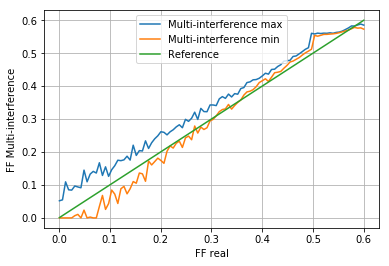

'\n#plot residuals\nmulti_residuals = FFreal-FFmulti\nfig, ax = plt.subplots()    \nax.plot(FFreal, multi_residuals,\'-\', label="Multi-interference residuals")\nlegend = ax.legend(loc=\'upper center\')\nplt.xlabel(\'FF real\')\nplt.ylabel(\'Residual error\')\nplt.grid()\nplt.show()'

In [78]:
#fitting com t2 por hamilton + ruido
FF = np.linspace(0.001, 0.6, 100)
FFmulti = (len(FF))
FFmulti=np.zeros(FFmulti)
FFreal = (len(FF))
FFreal=np.zeros(FFreal)

noise_level = 0.1
noise_counts = 10
FFmulti_list = np.zeros((noise_counts, len(FF)))
FFmulti_max = np.zeros(len(FF))
FFmulti_min = np.zeros(len(FF))

for n_count in range(0, noise_counts):
    for iteration,fatPercent in enumerate(FF):
        rf, rw = set_rho(fatPercent)

        xdata = discrete_timeseries(7)
        ydata = gen_GRE_t2_noise(xdata, rf, rw, noise_sd=noise_level)

        bd = (0, [np.inf, np.inf, 1])
        fitted_param, pcv = curve_fit(fit_multiinterf, xdata, ydata, bounds=bd)

        x_cont = continuous_timeseries()
        y_fit = fit_multiinterf(x_cont, *fitted_param)

        ff_calc = calc_fatfrac(fitted_param)

        FFmulti[iteration] = ff_calc
        FFreal[iteration] = fatPercent

    FFmulti_list[n_count,:] = FFmulti

FFmulti_max = np.amax(FFmulti_list, axis=0)
FFmulti_min = np.amin(FFmulti_list, axis=0)
      
        
        
#plot
fig, ax = plt.subplots()    
ax.plot(FFreal,FFmulti_max,'-', label="Multi-interference max")
ax.plot(FFreal,FFmulti_min,'-', label="Multi-interference min")
ax.plot(FFreal,FFreal,'-', label="Reference")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('FF Multi-interference')
plt.grid()
plt.show()
'''
#plot residuals
multi_residuals = FFreal-FFmulti
fig, ax = plt.subplots()    
ax.plot(FFreal, multi_residuals,'-', label="Multi-interference residuals")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('Residual error')
plt.grid()
plt.show()'''

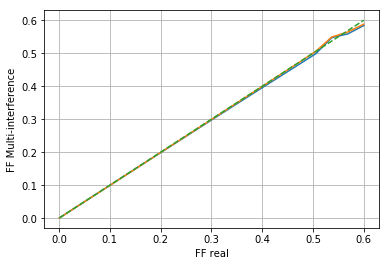

In [59]:
#fitting multi com t2 iguais a todas as parcelas

t2_values = np.linspace(0.01, 0.9, 2)
FF = np.linspace(0.001, 0.6, 20)

FFmulti = np.zeros([len(t2_values),len(FF)])
FFreal = np.zeros([len(t2_values),len(FF)])



for outer_iteration,t2 in enumerate(t2_values):  
    for iteration,fatPercent in enumerate(FF):
        rf, rw = set_rho(fatPercent)

        xdata = discrete_timeseries(7)
        ydata = gen_GRE_t2(xdata, rf, rw, np.zeros(7)+t2)

        bd = (0, [np.inf, np.inf, 1])
        fitted_param, pcv = curve_fit(fit_multiinterf, xdata, ydata, bounds=bd)

        x_cont = continuous_timeseries()
        y_fit = fit_multiinterf(x_cont, *fitted_param)

        ff_calc = calc_fatfrac(fitted_param)

        FFmulti[outer_iteration, iteration] = ff_calc
        FFreal[outer_iteration, iteration] = fatPercent


#print FFmulti[0,:]       
        
#plot
fig, ax = plt.subplots()  
for outer_iteration,t2 in enumerate(t2_values):
    ax.plot(FFreal[outer_iteration,:],FFmulti[outer_iteration,:],'-', label="Multi-interference calculation")
ax.plot(FFreal[0,:],FFreal[0,:],'--', label="Reference")
#legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('FF Multi-interference')
plt.grid()
plt.show()

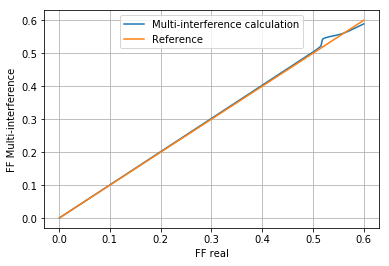

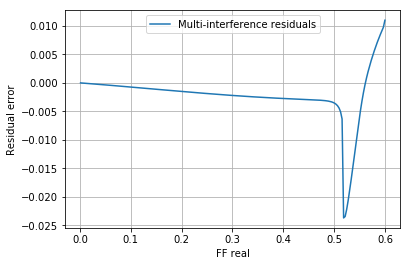

In [62]:
#fitting multi com t2 diferentes, um para agua e um para gordura

FF = np.linspace(0.001, 0.6, 200)
FFmulti = (len(FF))
FFmulti=np.zeros(FFmulti)
FFreal = (len(FF))
FFreal=np.zeros(FFreal)

for iteration,fatPercent in enumerate(FF):
    rf, rw = set_rho(fatPercent)

    xdata = discrete_timeseries(7)
    ydata = gen_GRE_t2(xdata, rf, rw, [0.8,0.8,0.8,0.8,0.8,0.8,0.2])

    bd = (0, [np.inf, np.inf, 1])
    fitted_param, pcv = curve_fit(fit_multiinterf, xdata, ydata, bounds=bd)

    x_cont = continuous_timeseries()
    y_fit = fit_multiinterf(x_cont, *fitted_param)

    ff_calc = calc_fatfrac(fitted_param)
    
    FFmulti[iteration] = ff_calc
    FFreal[iteration] = fatPercent

#plot
fig, ax = plt.subplots()    
ax.plot(FFreal,FFmulti,'-', label="Multi-interference calculation")
ax.plot(FFreal,FFreal,'-', label="Reference")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('FF Multi-interference')
plt.grid()
plt.show()

#plot residuals
multi_residuals = FFreal-FFmulti
fig, ax = plt.subplots()    
ax.plot(FFreal, multi_residuals,'-', label="Multi-interference residuals")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('Residual error')
plt.grid()
plt.show()